In [1]:
!pip install pyDOE

  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18170 sha256=7d1ce3395d37fdf5a564ab5d5274ba8da189132b5df55342613711de7dc06425
  Stored in directory: /root/.cache/pip/wheels/ce/b6/d7/c6b64746dba6433c593e471e0ac3acf4f36040456d1d160d17
Successfully built pyDOE


In [2]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax
import copy

from typing import Callable

from functools import partial

import tensorflow as tf
from pyDOE import lhs
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

In [3]:
# Number of data points to use
n_steps = 5

# Time step between samples
dt = 2.0

In [4]:
t0 = 0.0
tfinal = t0 + (n_steps-1)*dt

In [5]:
# Parameters of the model
k = 1.0
l = 2.0

In [6]:
def LorenzModel(t, w):
  x, y, z = w
  dwdt = [(1./(k**2+l**2)-1./k**2)*k*l*y*z,
          (1./l**2-1./(l**2+k**2))*k*l*x*z,
          0.5*(1./k**2-1./l**2)*k*l*x*y]
  return dwdt

In [7]:
# Define the collocation points over the domain [t_0, t_1]
def defineCollocationPoints(n_steps, N=100):

  try:
    n_steps > 1
  except:
    print('More than two steps required')

  t_points = np.array([t0 + i*dt for i in range(n_steps)])

  # Sample points where to evaluate the PDE
  ode_points = t_points[0] + (t_points[-1] - t_points[0])*lhs(1, N)

  # Sensor points
  z0 = np.random.uniform(-2, 2, (N,3))

  zsensors = np.zeros((N, n_steps, 3))
  tpoints = np.zeros((N, n_steps))

  for i in range(N):
    sol = solve_ivp(LorenzModel, [t_points[0], t_points[-1]], z0[i], t_eval=t_points).y.T
    zsensors[i] = sol
    tpoints[i] = t_points

  return (ode_points, tpoints, zsensors)

In [8]:
# Define the collocation points
(de_points, tpoints, zsensors) = defineCollocationPoints(n_steps, N=10000)

In [9]:
# Define the normalization layer
class Normalize(nn.Module):
  xmin: float
  xmax: float

  @nn.compact
  def __call__(self, x):
    return 2.0*(x-self.xmin)/(self.xmax - self.xmin) - 1.0

In [10]:
class HardConstraint(nn.Module):
  t0: float
  tfinal: float
  u0: float

  @nn.compact
  def __call__(self, inputs):
    t, nn = inputs
    return self.u0 + (t-self.t0)/(self.tfinal-self.t0)*nn

In [11]:
class CombineBranches(nn.Module):
  @nn.compact
  def __call__(self, inp1, inp2):
    mult = jnp.sum(inp1*inp2, axis=1)
    # For consistency, we add the batch dimension back here
    out = jnp.reshape(mult, (-1,1))
    return out

In [12]:
class MLP(nn.Module):

  layers: int
  units: int

  @nn.compact
  def __call__(self, inp):
    b = inp
    for i in range(self.layers-1):
      b = nn.Dense(self.units)(b)
      b = nn.tanh(b)
    out = nn.Dense(3*self.units, kernel_init=nn.initializers.normal(1e-3),
                   bias_init=nn.initializers.zeros)(b)
    return out

In [13]:
class DeepONet(nn.Module):

  layers: int
  units: int

  @nn.compact
  def __call__(self, t, tpoints, u):

    # Add the batch dimension
    if u.ndim == 2:
      u = u.reshape((1,u.shape[0], u.shape[1]))
    if tpoints.ndim == 1:
      tpoints = tpoints.reshape((1,-1))

    u = u.reshape((u.shape[0], -1))
    tpoints = tpoints.reshape((tpoints.shape[0], -1))

    # Stack into input data
    u = jnp.concatenate([u, tpoints], axis=1)

    # Add the batch dimension (for the collocation points)
    t = jnp.reshape(t, (-1,1))

    b = Normalize(tpoints.min(), tpoints.max())(t)
    trunk_net = MLP(self.layers, self.units)(b)
    branch_net = MLP(self.layers, self.units)(u)

    # Split into trunk/branch for q and p
    trunk_x1 = trunk_net[:,:self.units]
    trunk_x2 = trunk_net[:,self.units:2*self.units]
    trunk_x3 = trunk_net[:,2*self.units:]

    branch_x1 = branch_net[:,:self.units]
    branch_x2 = branch_net[:,self.units:2*self.units]
    branch_x3 = branch_net[:,2*self.units:]

    x1 = CombineBranches()(trunk_x1, branch_x1)
    x2 = CombineBranches()(trunk_x2, branch_x2)
    x3 = CombineBranches()(trunk_x3, branch_x3)

    # Remove the batch dimension
    x1 = jnp.reshape(x1, (-1,))
    x2 = jnp.reshape(x2, (-1,))
    x3 = jnp.reshape(x3, (-1,))

    return x1, x2, x3

In [14]:
# Create the model
deeponet = DeepONet(layers=6, units=40)

# Initialize the model parameters
params = deeponet.init(jax.random.PRNGKey(0), jnp.ones((10,)),
                       jnp.ones((10, n_steps)), jnp.ones((10, n_steps, 3)))

In [15]:
# DeepONet training function (standard DeepONet)
@jax.jit
def train_step(params, odes, tpoints, zpoints):
  t = odes[:,0]

  def w_model(t, tpoints, zpoints, component, params):
    return deeponet.apply(params, t, tpoints, zpoints)[component][0]
  def w(t, tpoints, zpoints, component, params):
    return jax.vmap(w_model, [0, 0, 0, None, None])(t, tpoints, zpoints, component, params)
  def w_t(t, tpoints, zpoints, component, params):
    return jax.vmap(jax.grad(w_model, 0), [0, 0, 0, None, None])(t, tpoints, zpoints, component, params)

  def loss(params, t, tpoints, zpoints):

    # Data loss
    zpred = []
    for i in range(n_steps):
      x1, x2, x3 = deeponet.apply(params, tpoints[:,i], tpoints, zpoints)
      zpred.append(jnp.stack([x1, x2, x3], axis=-1))
    zpred = jnp.array(zpred).transpose((1,0,2))
    data_loss = jnp.mean((zpred - zpoints)**2)

    # DE loss
    eqn1 = w_t(t, tpoints, zpoints, 0, params) - (1./(k**2+l**2)-1./k**2)*k*l*w(t, tpoints, zpoints, 1, params)*w(t, tpoints, zpoints, 2, params)
    eqn2 = w_t(t, tpoints, zpoints, 1, params) - (1./l**2-1./(l**2+k**2))*k*l*w(t, tpoints, zpoints, 0, params)*w(t, tpoints, zpoints, 2, params)
    eqn3 = w_t(t, tpoints, zpoints, 2, params) - 0.5*(1./k**2-1./l**2)*k*l*w(t, tpoints, zpoints, 0, params)*w(t, tpoints, zpoints, 1, params)
    de_loss = jnp.mean(eqn1**2 + eqn2**2 + eqn3**2)

    # Total loss
    loss = data_loss + de_loss

    return loss

  return jax.value_and_grad(loss)(params, t, tpoints, zpoints)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [16]:
def train_network(params, des, tpoints, zsensors, epochs=100):

  # Number of ICs and total number of DE collocation points
  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  # Learning rate schedule
  lr = 1e-3
  # schedule = optax.linear_schedule(lr, lr//10, epochs)
  optimizer = optax.adam(lr)

  opt_state = optimizer.init(params)

  ds_de = tf.data.Dataset.from_tensor_slices(des)
  ds_tpoints = tf.data.Dataset.from_tensor_slices(tpoints)
  ds_zpoints = tf.data.Dataset.from_tensor_slices(zsensors)

  ds = tf.data.Dataset.zip((ds_de, ds_tpoints, ds_zpoints))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.zeros(epochs)

  for i in range(epochs):

    for (des_batch, t_batch, z_batch) in ds:

      loss, grads = train_step(params, des_batch.numpy(), t_batch.numpy(), z_batch.numpy())
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 100 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [17]:
epochs = 1000
params, loss = train_network(params, de_points, tpoints, zsensors, epochs)

Loss in epoch 0: 0.013961856842041015
Loss in epoch 100: 0.0034695565700531006
Loss in epoch 200: 0.00249664306640625
Loss in epoch 300: 0.0016435060501098632
Loss in epoch 400: 0.0011808916330337525
Loss in epoch 500: 0.0005914408564567566
Loss in epoch 600: 0.0005085334777832031
Loss in epoch 700: 0.0003580125868320465
Loss in epoch 800: 0.0002753520607948303
Loss in epoch 900: 0.00023704709112644195


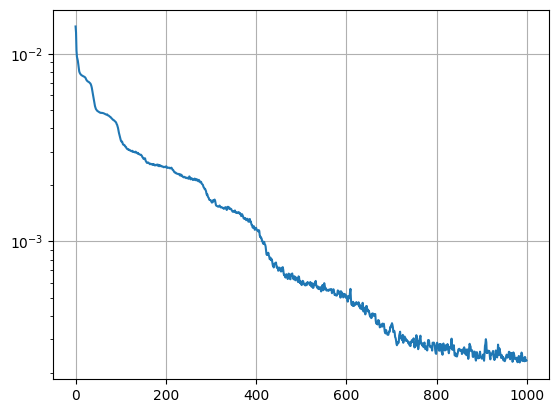

In [18]:
plt.semilogy(loss)
plt.grid()

### Test the model

In [19]:
# Grid where to evaluate the model
n = 500
t = np.linspace(t0, tfinal, n)

In [32]:
# Sample a new IC
(_, tpoints, zpoints) = defineCollocationPoints(n_steps, N=1)
init_data = zpoints[0, 0, :]
x1points, x2points, x3points = zpoints[0, :, 0], zpoints[0, :, 1], zpoints[0, :, 2]

In [33]:
# Model prediction
x1, x2, x3 = deeponet.apply(params, t, tpoints, zpoints)

In [34]:
def LorenzModel(t, w):
  x, y, z = w
  dwdt = [(1./(k**2+l**2)-1./k**2)*k*l*y*z,
          (1./l**2-1./(l**2+k**2))*k*l*x*z,
          0.5*(1./k**2-1./l**2)*k*l*x*y]
  return dwdt

sol_rk = solve_ivp(LorenzModel, [t0, tfinal], init_data, t_eval=t).y.T
x1rk, x2rk, x3rk = sol_rk[:,0], sol_rk[:,1], sol_rk[:,2]

Text(0.5, 1.0, 'Solution time series')

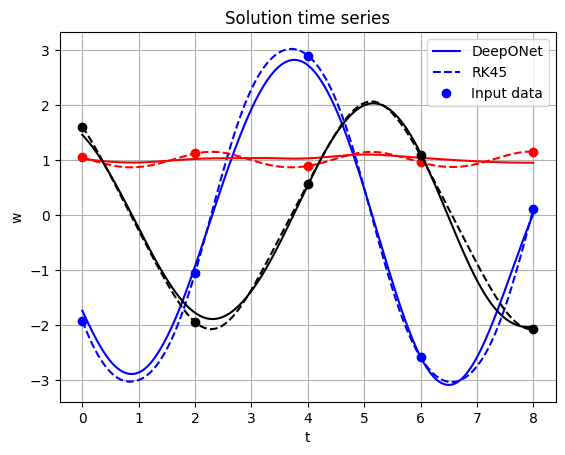

In [35]:
plt.plot(t, x1,'b')
plt.plot(t, x1rk,'b--')
plt.plot(tpoints[0,], x1points, 'bo')

plt.plot(t, x2, 'r')
plt.plot(t, x2rk, 'r--')
plt.plot(tpoints[0,], x2points, 'ro')

plt.plot(t, x3, 'k')
plt.plot(t, x3rk, 'k--')
plt.plot(tpoints[0,], x3points, 'ko')

plt.legend(['DeepONet', 'RK45', 'Input data'])
plt.grid()
plt.xlabel('t')
plt.ylabel('w')
plt.title('Solution time series')